# How certain are the reconstructed ancestors?

The ancestral repertoires are predictions for the most probable residue at every site of each
reconstructed node. Two things limit how far they can be trusted: whether the node exists in the tree
(bootstrap support of the split it subtends) and how probable its sequence is (the marginal posterior
probability of each residue). Both are read here from the IQ-TREE runs of
`Ancestral_Receptor_Reconstruction/human_tree_asr_hagfish_outgroup/`, which are not modified.

Node names are tree labels; paper node k is tree `node_{k+1}`. A site counts as ambiguous when the
second most probable residue has a posterior of at least 0.2, the usual threshold for building an
alternative ("AltAll") ancestor.

In [1]:
import subprocess
import sys
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ete4 import Tree

REPO = Path("../..").resolve()
sys.path.append(str(REPO / "Supplementary_Material"))
import robustness_checks as rc  # noqa: F401  (puts the shared script folders on the path)
from plotting_functions import custom_plots, FIGSIZE
from activation_figures import INK, MUTED, save

plt.rcParams.update(custom_plots())
plt.rcParams.update(rc.TEXT_SIZES)

ASR = REPO / "Ancestral_Receptor_Reconstruction/human_tree_asr_hagfish_outgroup"
NAMED_TREE = ASR / "PF13853_9606.7764.mafft.lg.treefile.rooted.withinternalnames"
SUPPORT_TREE = ASR / "PF13853_9606.7764.mafft.lg.treefile"
FOUNDING_NODES = {"node_1": 0, "node_2": 1, "node_3": 2, "node_4": 3, "node_5": 4, "node_6": 5}

TABLES = Path("Tables")
FIGURES = Path("Figures")
TABLES.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)

## Posterior probability of each ancestral sequence

Each node was reconstructed over the alignment columns it possessed (its mask). For every node: the
mean and median posterior probability of the chosen residue over those columns, the share of sites
below 0.8, and the number of ambiguous sites.

In [2]:
def node_posteriors(folder):
    """Posterior summary of one reconstructed node, from its own IQ-TREE .state file."""
    name = folder.name.replace("NODE_", "")
    state_file = next(folder.glob("*.state"))
    # The .state file lists every node of the tree; awk keeps the rows of this one.
    rows = subprocess.run(["awk", "-v", f"node={name}", "$1 == node", str(state_file)],
                          capture_output=True, text=True).stdout.strip().split("\n")
    rows = [row.split("\t") for row in rows if row]
    if not rows:
        return dict(node=name, sites=0)
    probabilities = np.array([[float(value) for value in row[3:]] for row in rows])
    ranked = np.sort(probabilities, axis=1)
    best, second = ranked[:, -1], ranked[:, -2]
    return dict(node=name, sites=len(rows), mean_posterior=best.mean(), median_posterior=np.median(best),
                pct_sites_below_0_8=100 * (best < 0.8).mean(), ambiguous_sites=int((second >= 0.2).sum()))


folders = sorted(ASR.glob("NODE_node_*"))
with ProcessPoolExecutor(32) as pool:
    posteriors = pd.DataFrame(list(pool.map(node_posteriors, folders)))
posteriors["tree_number"] = posteriors.node.str.replace("node_", "").astype(int)
posteriors = posteriors[posteriors.sites > 0].sort_values("tree_number").reset_index(drop=True)
posteriors.insert(1, "paper_node", posteriors.tree_number - 1)
print(f"nodes with states: {len(posteriors)}")
posteriors[["mean_posterior", "pct_sites_below_0_8", "ambiguous_sites"]].describe().round(3)

nodes with states: 432


,mean_posterior,pct_sites_below_0_8,ambiguous_sites
count,432.000,432.000,432.000
mean,0.928,13.811,29.667
std,0.045,8.439,16.495
min,0.676,0.000,0.000
25%,0.902,8.032,18.000
50%,0.928,13.738,31.000
75%,0.959,19.185,40.000
max,1.000,57.556,103.000


## Bootstrap support of the nodes

The UFBoot support of each node is the support of the split it subtends in the IQ-TREE tree with
1,000 ultrafast bootstrap replicates. Node 0 (tree `node_1`) is the ingroup itself, whose split from
the outgroup is the root and has no support value.

In [3]:
named = Tree(open(NAMED_TREE).read(), parser=1)
supported = Tree(open(SUPPORT_TREE).read(), parser=0)
all_leaves = frozenset(supported.leaf_names())
support_of_split = {}
for node in supported.traverse():
    if node.is_leaf or node.is_root:
        continue
    leaves = frozenset(node.leaf_names())
    support_of_split[leaves] = node.support
    support_of_split[all_leaves - leaves] = node.support

support, distance_from_root = {}, {}
for node in named.traverse():
    if node.is_leaf or not node.name:
        continue
    support[node.name] = support_of_split.get(frozenset(node.leaf_names()))
    distance_from_root[node.name] = named.get_distance(named, node)
posteriors["ufboot"] = posteriors.node.map(support)
posteriors["distance_from_root"] = posteriors.node.map(distance_from_root)
posteriors.to_csv(TABLES / "ancestral_node_confidence.csv", index=False)

founding = posteriors[posteriors.node.isin(FOUNDING_NODES)]
founding.round(3)

,node,paper_node,sites,mean_posterior,median_posterior,pct_sites_below_0_8,ambiguous_sites,tree_number,ufboot,distance_from_root
0,node_1,0,311,0.676,0.698,57.556,103.0,1,NaN,1.512
1,node_2,1,314,0.745,0.848,46.815,86.0,2,99.0,2.000
2,node_3,2,311,0.734,0.842,45.338,81.0,3,100.0,1.869
3,node_4,3,315,0.906,0.997,18.730,41.0,4,96.0,2.473
4,node_5,4,314,0.810,0.946,36.624,81.0,5,100.0,2.737
5,node_6,5,312,0.866,0.980,25.641,48.0,6,100.0,2.417


The deepest nodes, where the founding duplications happen, are the least certain sequences of the
tree. They are well supported as splits (UFBoot 96-100), but their sequences are not: node 0 has a mean
posterior of about 0.68 and node 1 and node 2 about 0.74, against a median of about 0.93 over all 432
nodes, and they have 103, 86 and 81 ambiguous sites. The repertoires of these nodes are therefore predictions
for the most probable sequence among many close alternatives. Predicting the alternative ("AltAll")
sequences of nodes 0, 1, 2 and 5, and checking that their repertoires keep the acid and aromatic gains,
is the test that would remove this uncertainty.

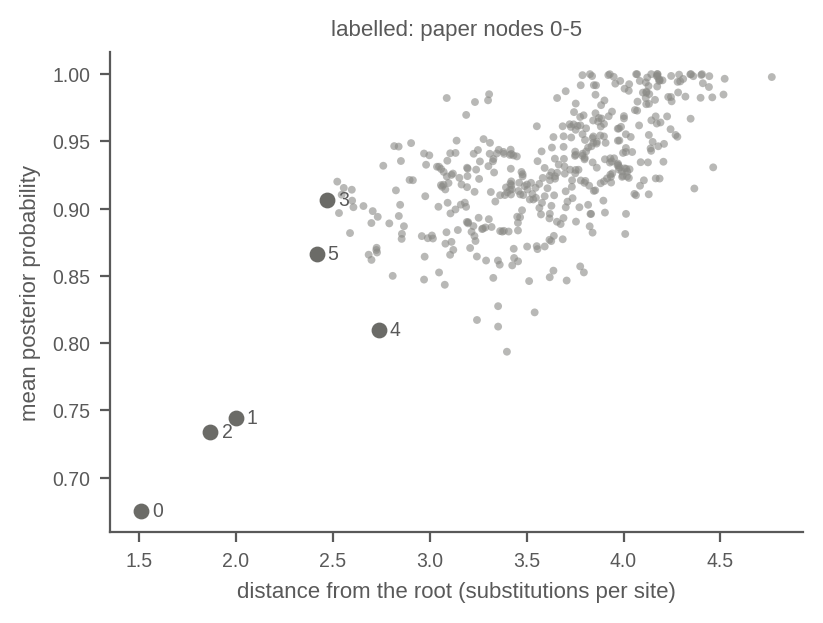

In [4]:
figure, axis = plt.subplots(figsize=FIGSIZE, layout="constrained")
axis.scatter(posteriors.distance_from_root, posteriors.mean_posterior, s=8, color=MUTED, alpha=0.6,
             edgecolor="none", label="ancestral node")
for _, row in founding.iterrows():
    axis.scatter(row.distance_from_root, row.mean_posterior, s=22, color=INK, zorder=3)
    axis.annotate(f"{int(row.paper_node)}", (row.distance_from_root, row.mean_posterior),
                  xytext=(4, -2), textcoords="offset points", fontsize=7)
axis.set_xlabel("distance from the root (substitutions per site)")
axis.set_ylabel("mean posterior probability")
axis.set_title("labelled: paper nodes 0-5", fontsize=8)
save(figure, FIGURES / "posterior_by_depth.svg", show=True)